# UCLA resting BOLD: active all-parcel HRF and relative input inversion

## Problem
Recover regional hemodynamic kernels and model-conditioned latent inputs from real measured fMRI. Blind amplitude/timing are not physiologically unique; unit point-event amplitude fixes this estimator’s scale. No independently recorded neural truth is available.

## Data
The complete author surface files contain152retained scans, not156. Independent Schaefer anatomical averaging produces all400parcel time courses before inference; no fit-based ROIselection. SidecarTR2s,TE30ms,3TTrioTim; nominal312sscan time does not justify inventing missing samples or a known removal history.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct,submission
from src.visualization import make_figures,roi_residual
import matplotlib.pyplot as plt
data=load_data(ROOT/'data/raw_data.npz')
print('All observed parcel/sample dimensions:',data['bold'].shape)
print('Independent atlas vertex count min/max:',data['vertex_counts'].min(),data['vertex_counts'].max())

All observed parcel/sample dimensions: (400, 152)
Independent atlas vertex count min/max: 20 120


## Physics

Normalized BOLDy is related to relative inputx through regional HRFh: y(t)=Σh(j)x((t−j)mod152)+error. The scan-grid kernel has13samples at2sintervals, obtained from37microtime samples with2/3sintervals. Causal event-basis fitting uses zero prehistory; the finite spectral inverse uses periodic convolution. These are numerical conventions, not assertions of periodic brain activity. HRFamplitude is standardized BOLD per unit discrete input; the recovered input has no firing-rate units. No extra integration-step factor is applied.

## Method

The active default fits canonical/time-derivative/dispersion-derivative HRFcolumns, local BOLDpeak events,4–8sonset-delay candidates and explicit AR1Cochrane–OrcuttGLS. A closed-form Fourier ridge inverse uses λ=.1mean|H|². Sourcefilter functions mutate and return the same array, so its later.01–.08Hzfilter also alters aliased deconvolution input. This measured original flow is deliberately preserved and disclosed, rather than silently corrected. Original standalone400ROIexecution, stage fixtures and local independent physics tests establish this binding.

In [2]:
start=time.perf_counter();fresh=reconstruct(data);runtime=time.perf_counter()-start
print('Full fresh400ROI reconstruction seconds:',runtime)
print('HRF/relative input:',fresh['hrf'].shape,fresh['neural_drive'].shape)
print('Events per ROI min/max:',fresh['events'].sum(axis=1).min(),fresh['events'].sum(axis=1).max())
print('Selected lag microbins and counts:',np.unique(fresh['coefficients'][-1],return_counts=True))
print('All quantities finite:',all(np.isfinite(fresh[k]).all() for k in ['hrf','neural_drive']))

Full fresh400ROI reconstruction seconds: 2.796186099993065
HRF/relative input: (1, 400, 37) (1, 400, 152)
Events per ROI min/max: 4 12
Selected lag microbins and counts: (array([ 8., 10., 11., 12.]), array([  3, 313,  81,   3]))
All quantities finite: True


## Results
Original author execution and fresh local execution use exactly the same400regional observations. The following canonical-only ablation is also a fresh complete400ROIreconstruction. It diagnoses model dependence and does not provide independent neural validation. All regions remain in the comparison; illustrative trace indices were fixed before looking at outcomes.

Fresh all400ROI canonical-only ablation seconds: 5.41687820001971


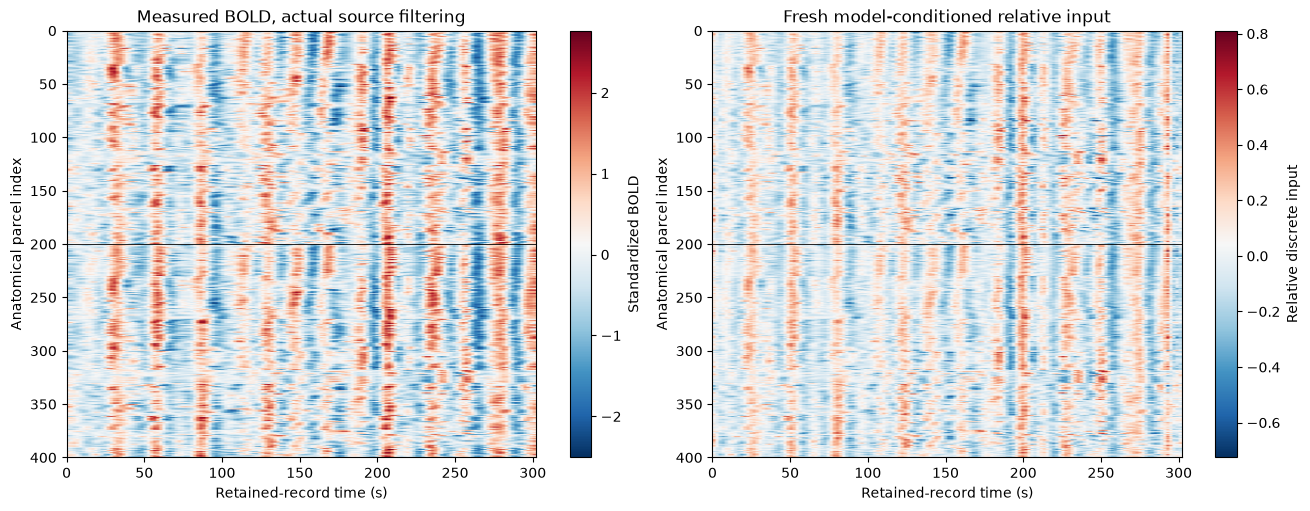

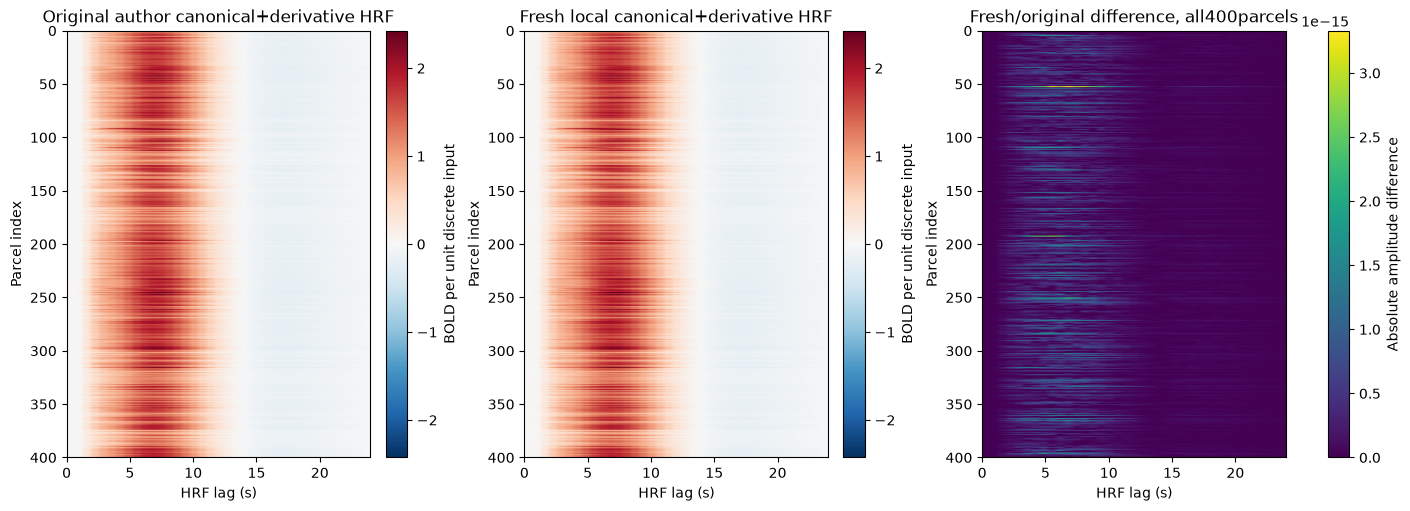

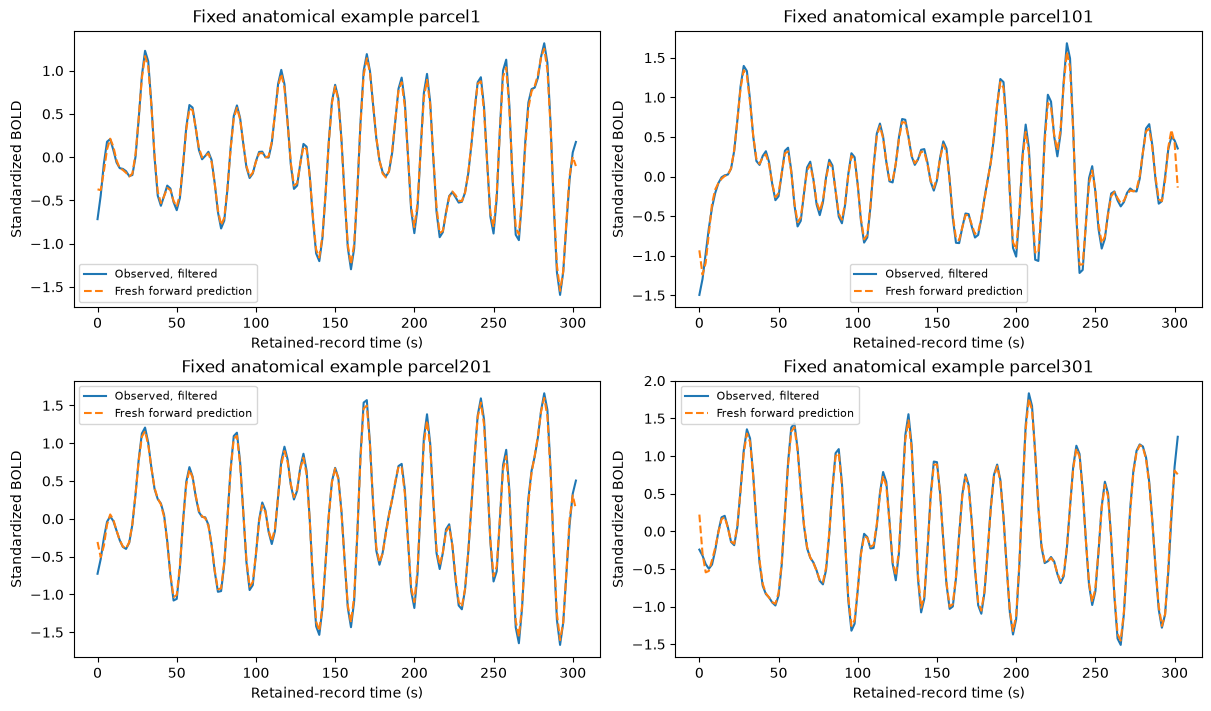

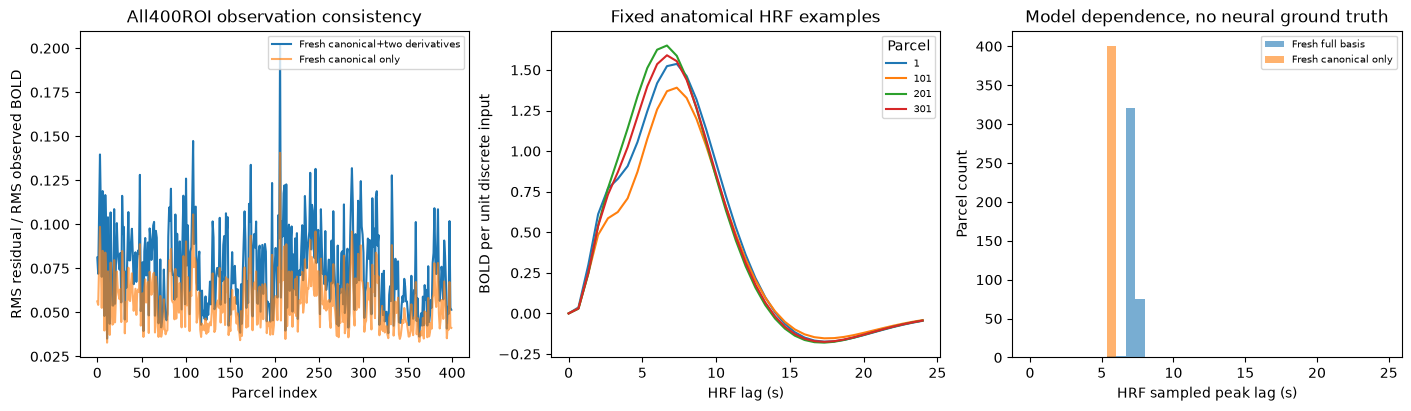

In [3]:
start=time.perf_counter();ablation=reconstruct(data,derivatives=0);ablation_runtime=time.perf_counter()-start
print('Fresh all400ROI canonical-only ablation seconds:',ablation_runtime)
original=np.load(ROOT/'notebooks/reference_outputs/original_method.npz',allow_pickle=False)
figures=make_figures(data,fresh,original,ablation)
for fig in figures:display(fig)
plt.close('all')

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
ref=judge.load_arrays(ROOT/'evaluation/baseline_reference.npz')
y=judge.filtered_observations(data['bold'][None])
metrics=judge.score(submission(fresh),ref,y)
bounds=json.loads((ROOT/'evaluation/metrics.json').read_text())['boundaries']
passed=all(metrics[k]>=v if k.endswith('_ncc') else metrics[k]<=v for k,v in bounds.items())
print(json.dumps(metrics,indent=2));print('All fixed metrics:',passed);assert passed
print('Full vs canonical-only worst ROI forward residual:',max(roi_residual(fresh)),max(roi_residual(ablation)))

{
  "hrf_ncc": 1.0000000000000002,
  "hrf_nrmse": 9.80739950678231e-17,
  "worst_roi_hrf_nrmse": 8.999007216110058e-16,
  "neural_drive_ncc": 0.9999999999999998,
  "neural_drive_nrmse": 1.2713896580014325e-14,
  "worst_roi_drive_nrmse": 8.50356161577687e-14,
  "worst_roi_observation_residual": 0.20152144162046928
}
All fixed metrics: True
Full vs canonical-only worst ROI forward residual: 0.20152144162046928 0.14058693076981646


## Conclusion
The complete fresh reference path reproduces original HRFsand relative inputs on every supplied parcel, with independently checked convolution and ridge normal equations. The basis ablation exposes model dependence in recovered response timing. Neither inferred point events, matching method references nor a small forward residual establishes true firing activity. Physiological/motion confounds, assumed linear coupling, amplitude convention and finite-record boundaries remain explicit limits.